# Supplementary analyses and model specifications

This notebook exposes the material reported in the manuscript's supplement that the seven analysis
notebooks do not display directly: the machine-readable specifications of the six frozen
institution-held-out minimal Cox models (Supplementary Table S31), the post hoc proportional-hazards
assessment of the frozen Cox models (S34), and the supplementary tables on sample support,
hyperparameters, paired complexity comparisons, importance values and predicted-risk percentiles
(S36 to S40).

**Nothing here refits a model for prediction or changes a frozen result.** Each runner takes a
SHA-256 snapshot of `analysis/out/current/` before it starts and asserts that the snapshot is
unchanged when it finishes. The only new estimation is the proportional-hazards test itself, which is
evaluated at the frozen coefficients, and the percentile summary of already-frozen held-out
predictions. All outputs are aggregate and are written under `analysis/out/current/supplementary/`.

The three runners live in `scripts/` so they can also be executed from the command line; this
notebook runs them in order and displays their outputs. It requires the outputs of notebooks 01 to 07
and of the forest runners, and `Rscript` with the restored `r/renv` library for the
proportional-hazards step.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
CURRENT = PROJECT_ROOT / "analysis" / "out" / "current"
SUPP = CURRENT / "supplementary"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def run(script: str) -> dict:
    """Run one runner from the repository root and return the JSON summary it prints."""
    env = {**os.environ, "PYTHONPATH": str(PROJECT_ROOT / "src")}
    completed = subprocess.run(
        [sys.executable, str(PROJECT_ROOT / "scripts" / script)],
        cwd=PROJECT_ROOT, env=env, capture_output=True, text=True, check=True,
    )
    text = completed.stdout.strip()
    return json.loads(text[text.index("{"):])

## 1. Model specifications (Supplementary Table S31)

`scripts/export_models.py` loads each frozen minimal Cox bundle through the registry (verifying its
hash), writes a self-contained JSON specification with predictor coding, imputation and pooling
rules, coefficients, centring means and baseline survival, and then rebuilds every held-out
patient's prediction from the JSON alone using `scripts/predict.py`, a standard-library predictor
with no project imports. The rebuilt predictions must match the saved bundle on both risk scales to
within an absolute tolerance of 1e-9.

In [2]:
export_summary = run("export_models.py")
display(export_summary)
spec_dir = SUPP / "model_specification"
display(pd.DataFrame(json.loads((spec_dir / "manifest.json").read_text())["models"]))
display(pd.DataFrame(json.loads((spec_dir / "verification.json").read_text()))[
    ["model_id", "assessment_patients", "synthetic_profiles", "max_absolute_error", "atol", "status"]
])

{'models_verified': 6,
 'max_absolute_error': 2.220446049250313e-16,
 'assessment_rows': 982,
 'frozen_files_unchanged': 1262}

,model_id,filename,sha256
0,endpoint=OS|design=iecv_outer|holdout=DFCI|mod...,OS_DFCI.json,12e72b0475c9810ce7d980931b92c35d522cf0e3a597e5...
1,endpoint=OS|design=iecv_outer|holdout=MSK|mode...,OS_MSK.json,0fbaa0f4aa60b938fc729473990d5f0152c294aecc724b...
2,endpoint=OS|design=iecv_outer|holdout=VICC|mod...,OS_VICC.json,50430323dc7c29066b9c8981954b2560cef8d5281dceea...
3,endpoint=TTNT-D|design=iecv_outer|holdout=DFCI...,TTNT-D_DFCI.json,8716378b4ea731eb0d2b6bf917f8fffa43198451e424c9...
4,endpoint=TTNT-D|design=iecv_outer|holdout=MSK|...,TTNT-D_MSK.json,b385597c6f884bdd305ad9df0b9feca7b9b8e53c926ed4...
5,endpoint=TTNT-D|design=iecv_outer|holdout=VICC...,TTNT-D_VICC.json,27c23634968bfe4c15935a9ee7860d0657f893aafa297d...


,model_id,assessment_patients,synthetic_profiles,max_absolute_error,atol,status
0,endpoint=OS|design=iecv_outer|holdout=DFCI|mod...,227,21,2.220446e-16,1.000000e-09,passed
1,endpoint=OS|design=iecv_outer|holdout=MSK|mode...,330,18,1.110223e-16,1.000000e-09,passed
2,endpoint=OS|design=iecv_outer|holdout=VICC|mod...,87,20,1.110223e-16,1.000000e-09,passed
3,endpoint=TTNT-D|design=iecv_outer|holdout=DFCI...,126,21,2.220446e-16,1.000000e-09,passed
4,endpoint=TTNT-D|design=iecv_outer|holdout=MSK|...,180,18,1.110223e-16,1.000000e-09,passed
5,endpoint=TTNT-D|design=iecv_outer|holdout=VICC...,32,20,2.220446e-16,1.000000e-09,passed


In [3]:
coefficients = pd.read_csv(spec_dir / "coefficients.csv")
display(
    coefficients.assign(model=coefficients["endpoint"] + " / " + coefficients["held_out"] + " held out")
    .pivot(index="feature", columns="model", values="coefficient")
    .round(4)
)
display(pd.read_csv(spec_dir / "baseline_horizons.csv").round(4))

model,OS / DFCI held out,OS / MSK held out,OS / VICC held out,TTNT-D / DFCI held out,TTNT-D / MSK held out,TTNT-D / VICC held out
feature,,,,,,
age_at_folfox,0.1257,0.1570,0.1334,0.0107,0.0573,0.0267
ca_d_site__C18.0,0.2957,0.3983,0.4586,-0.0999,0.4173,0.0563
ca_d_site__C18.2,0.3331,0.2340,-0.0562,-0.1672,0.5249,-0.3390
ca_d_site__C18.4,-0.2639,-0.0337,-0.2045,-0.3653,0.0741,-0.4151
ca_d_site__C18.5,0.3375,NaN,0.5133,NaN,NaN,NaN
ca_d_site__C18.6,-0.1099,-0.1707,-0.1921,0.7038,1.9361,0.9780
ca_d_site__C18.7,-0.1745,NaN,NaN,-0.5880,NaN,-0.4798
ca_d_site__C18.9,0.9772,0.7945,1.0579,NaN,NaN,0.1722
ca_d_site__C19.9,-0.0475,0.1413,0.1338,-0.3151,NaN,-0.1121


,endpoint,held_out,horizon,baseline_survival
0,OS,DFCI,365,0.9316
1,OS,DFCI,730,0.7771
2,OS,MSK,365,0.9402
3,OS,MSK,730,0.7914
4,OS,VICC,365,0.9360
5,OS,VICC,730,0.7917
6,TTNT-D,DFCI,365,0.3876
7,TTNT-D,DFCI,730,0.2102
8,TTNT-D,MSK,365,0.5009
9,TTNT-D,MSK,730,0.2535


### Worked example

One synthetic predictor profile per model, with its 730-day unconditional risk and the risk
conditional on having entered observation 215 days after FOLFOX initiation. The profiles are
invented; they illustrate how the exported files are used and are not patient data.

In [4]:
examples = json.loads((spec_dir / "synthetic_examples.json").read_text())
display(pd.DataFrame(
    [{"model_file": e["model_file"], **e["synthetic_profile"],
      "unconditional_730": round(e["unconditional_730"], 4),
      "entry_conditional_730": round(e["entry_conditional_730"], 4)} for e in examples]
))

,model_file,age_at_folfox,metastatic_presentation,ca_d_site,number_metastatic_sites,unconditional_730,entry_conditional_730
0,OS_DFCI.json,55.0,Recurrent/metachronous,C20.9,2.0,0.1093,0.1024
1,OS_MSK.json,55.0,Recurrent/metachronous,C18.7,2.0,0.0967,0.0882
2,OS_VICC.json,55.0,Recurrent/metachronous,C18.7,2.0,0.0997,0.0911
3,TTNT-D_DFCI.json,55.0,Recurrent/metachronous,C20.9,2.0,0.6766,0.5186
4,TTNT-D_MSK.json,55.0,Recurrent/metachronous,C18.7,2.0,0.4263,0.3332
5,TTNT-D_VICC.json,55.0,Recurrent/metachronous,C20.9,2.0,0.6074,0.4525


## 2. Proportional-hazards assessment (Supplementary Table S34)

`scripts/run_ph_assessment.py` first runs an engine-admission check on simulated left-truncated
data, confirming that the R `survival::cox.zph` route reproduces an independent Schoenfeld-residual
reference under delayed entry and that the ridge-penalised form of the test agrees with `cox.zph`
when the penalty is zero. It then evaluates the Grambsch-Therneau test at the frozen coefficients of
the minimal Cox models (OS and TTNT-D) and the spline Cox model (OS) in each development scope, with
Holm adjustment across terms within a model. The prespecified trigger rule for a time-varying
sensitivity analysis fires only when the same term, or the global test, is flagged in at least two
of the three OS minimal-Cox scopes.

In [5]:
ph_summary = run("run_ph_assessment.py")
display({"admission": {k: v for k, v in ph_summary["admission"].items() if "passed" in k},
         "frozen_files": ph_summary["frozen_files"]})
ph_dir = SUPP / "ph_assessment"
tests = pd.read_csv(ph_dir / "ph_tests.csv")
primary = tests[(tests["transform"] == "km") & (tests["model"] == "minimal_cox")]
display(primary[["endpoint", "held_out_institution", "term", "chisq", "df", "p_value", "p_holm", "n", "events", "flag"]]
        .round(4).reset_index(drop=True))

{'admission': {'penalised_passed': True, 'passed': True}, 'frozen_files': 1262}

,endpoint,held_out_institution,term,chisq,df,p_value,p_holm,n,events,flag
0,OS,DFCI,age_at_folfox,0.0964,1,0.7562,1.0000,417,232,False
1,OS,DFCI,metastatic_presentation,0.2359,1,0.6272,1.0000,417,232,False
2,OS,DFCI,ca_d_site,3.6066,9,0.9353,1.0000,417,232,False
3,OS,DFCI,number_metastatic_sites,2.1697,1,0.1408,0.5630,417,232,False
4,OS,DFCI,GLOBAL,6.7272,12,0.8751,NaN,417,232,False
5,OS,MSK,age_at_folfox,3.6245,1,0.0569,0.1708,314,183,False
6,OS,MSK,metastatic_presentation,1.9677,1,0.1607,0.3214,314,183,False
7,OS,MSK,ca_d_site,7.1688,8,0.5185,0.5185,314,183,False
8,OS,MSK,number_metastatic_sites,8.4023,1,0.0037,0.0150,314,183,True
9,OS,MSK,GLOBAL,20.1985,11,0.0427,NaN,314,183,True


In [6]:
trigger = json.loads((ph_dir / "ph_trigger.json").read_text())
display({k: trigger[k] for k in ("rule", "primary_flags_by_term", "trigger_fired", "firing_terms")})
display(pd.DataFrame(trigger["non_triggering_flags"]))
spline = tests[(tests["transform"] == "km") & (tests["model"] == "spline_cox") & tests["flag"]]
display(spline[["endpoint", "held_out_institution", "term", "chisq", "df", "p_holm", "status"]].round(4).reset_index(drop=True))

{'rule': 'Trigger fires when the same term, or the global test, is flagged in at least two of the three OS minimal-Cox development scopes on the Kaplan-Meier transform. A term is flagged at Holm-adjusted p < 0.05 within model; the global test at p < 0.05.',
 'primary_flags_by_term': {'GLOBAL': ['MSK'],
  'number_metastatic_sites': ['MSK']},
 'trigger_fired': False,
 'firing_terms': {}}

,endpoint,model,held_out_institution,term
0,TTNT-D,minimal_cox,DFCI,number_metastatic_sites
1,TTNT-D,minimal_cox,DFCI,GLOBAL
2,TTNT-D,minimal_cox,MSK,number_metastatic_sites
3,TTNT-D,minimal_cox,VICC,number_metastatic_sites
4,TTNT-D,minimal_cox,VICC,GLOBAL
5,OS,spline_cox,MSK,dmets_pelvis
6,OS,spline_cox,MSK,dmets_thorax
7,OS,spline_cox,VICC,GLOBAL


,endpoint,held_out_institution,term,chisq,df,p_holm,status
0,OS,MSK,dmets_pelvis,10.4682,1,0.0173,computed
1,OS,MSK,dmets_thorax,10.5631,1,0.0173,computed
2,OS,VICC,GLOBAL,50.5221,35,NaN,computed


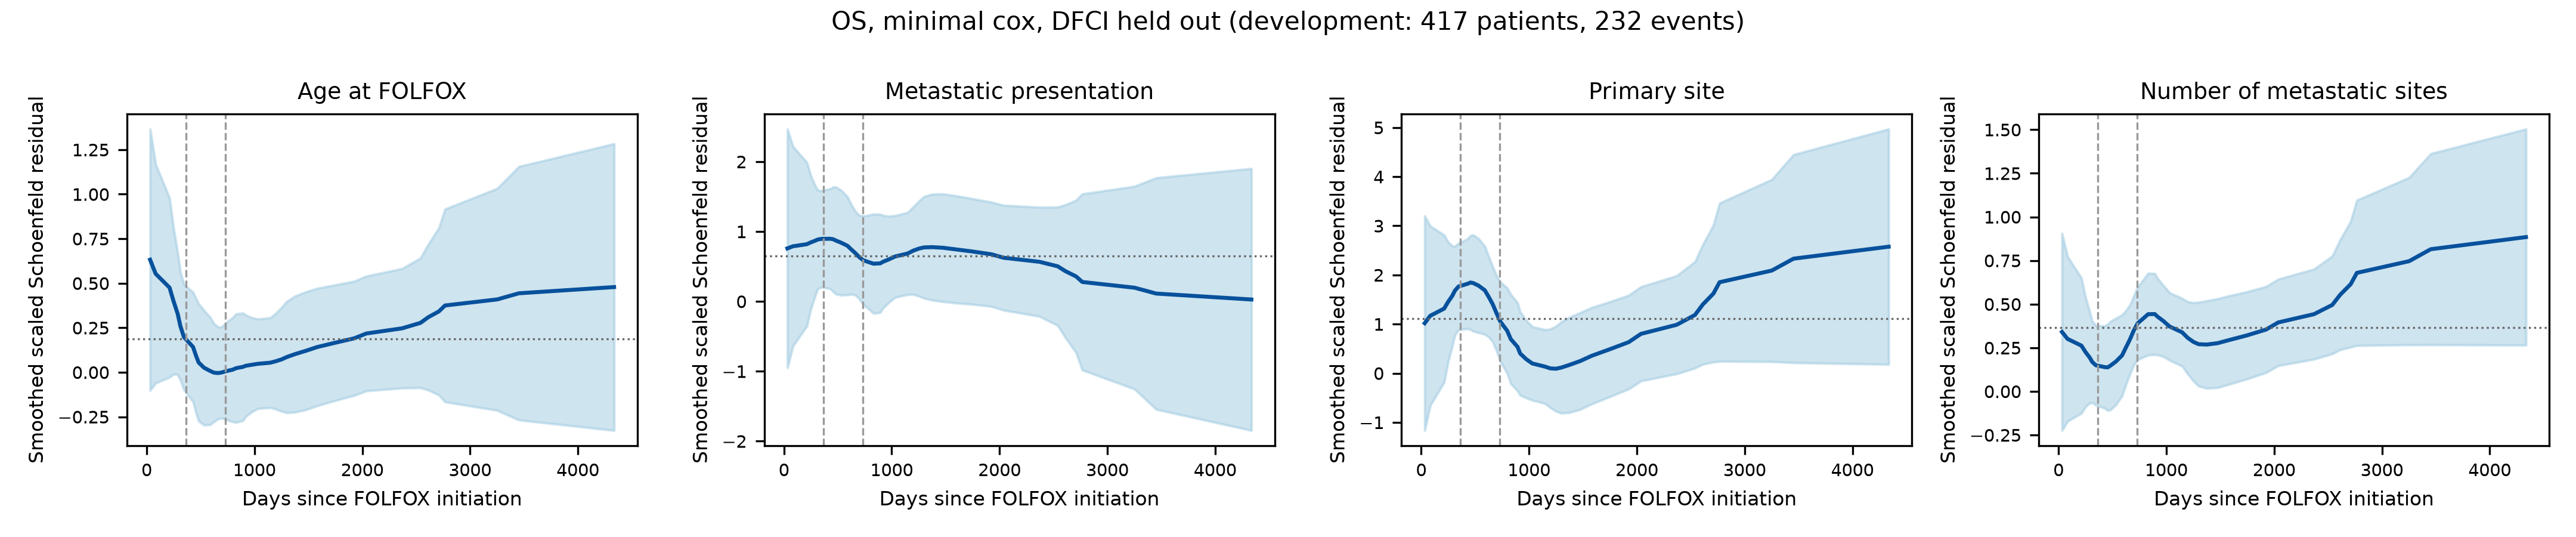

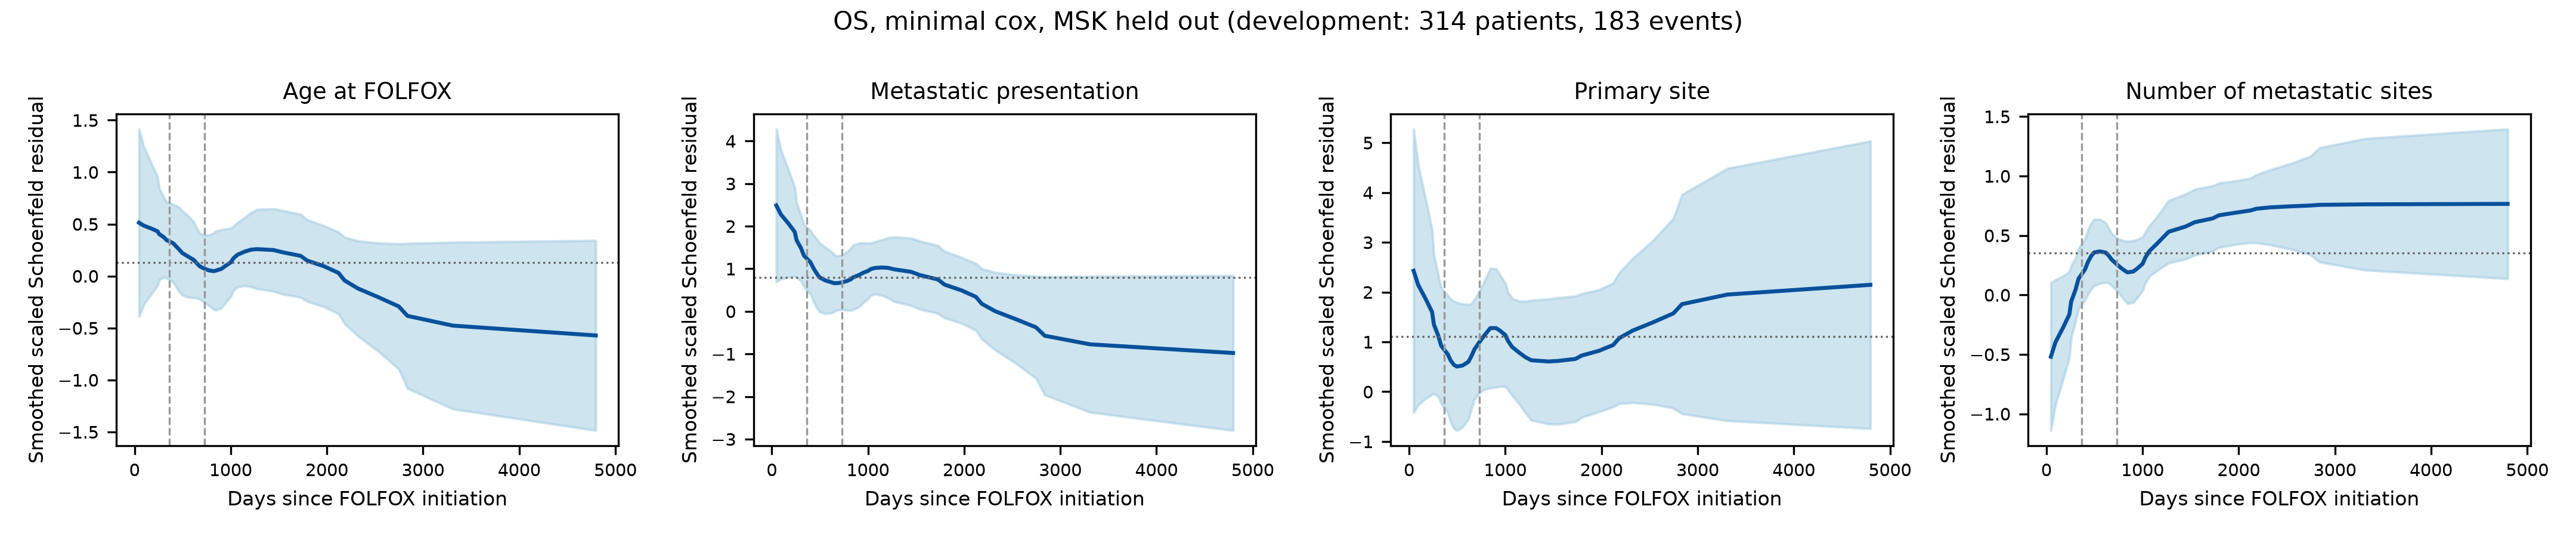

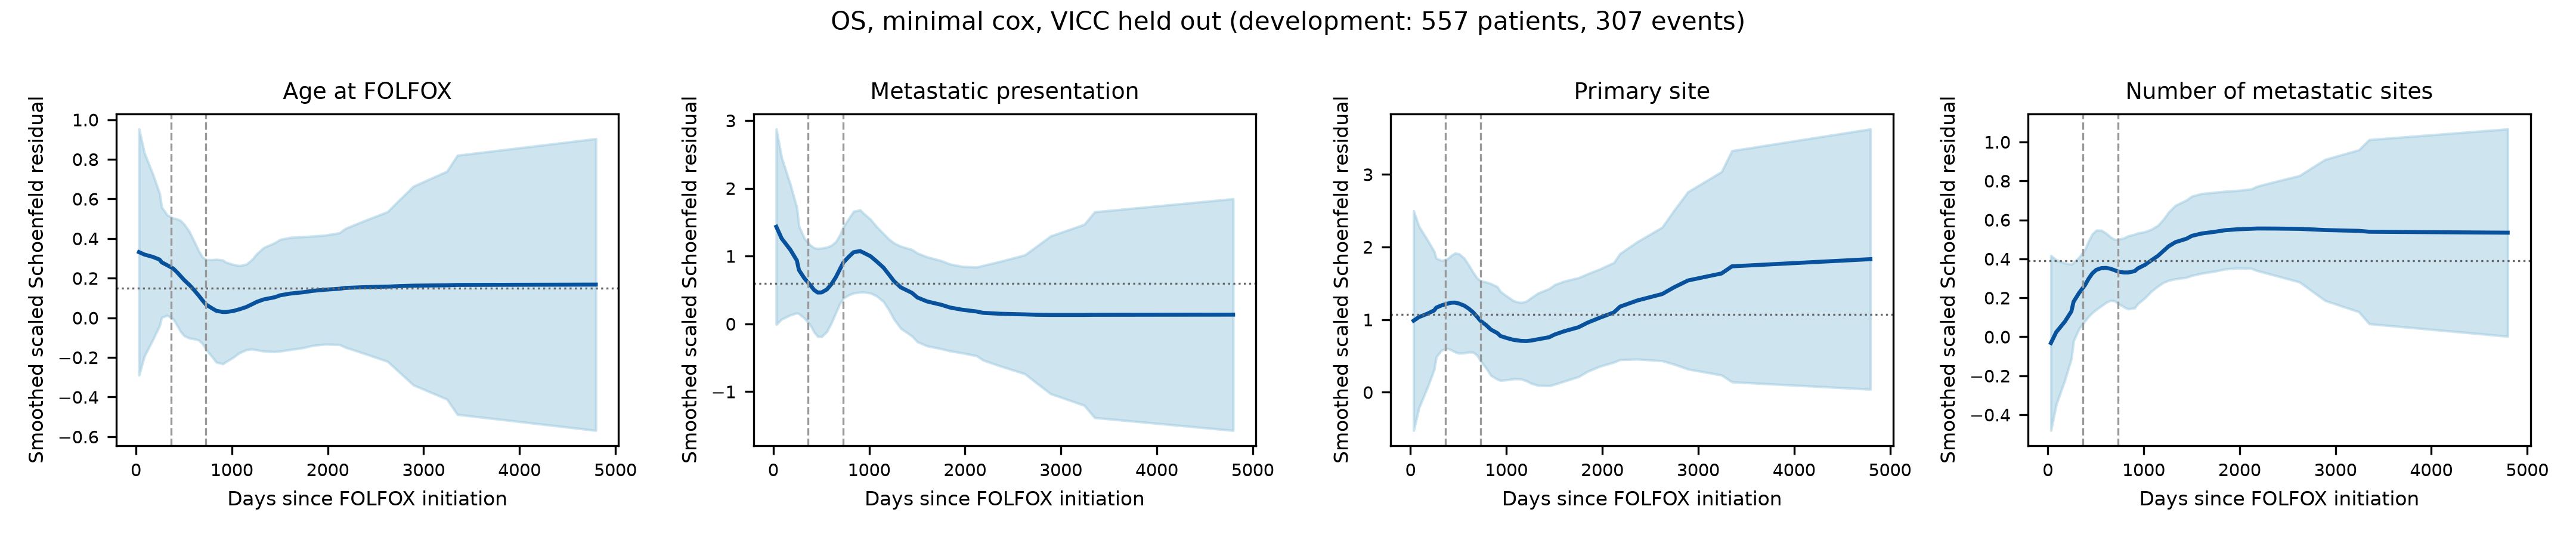

In [7]:
for centre in ("DFCI", "MSK", "VICC"):
    display(Image(filename=str(ph_dir / f"ph_residuals_OS_minimal_cox_{centre}.png"), width=900))

## 3. Supplementary tables S36 to S40

`scripts/package_supplement.py` assembles, from the frozen evaluation, optimisation, explainability
and forest outputs: development and evaluation support with finite-bootstrap fractions (S36), the
selected hyperparameters and candidate grids (S37), every paired complexity comparison with its
materiality margin and locked classification (S38), the minimal-Cox importance values behind the
rank comparisons (S39), and percentiles of the held-out predicted risks (S40). It also copies the
proportional-hazards outputs into S34.

In [8]:
supplement_summary = run("package_supplement.py")
display(supplement_summary)
data = SUPP / "supplementary_data"
display(pd.read_csv(data / "S36" / "development_support.csv"))
display(pd.read_csv(data / "S36" / "evaluation_support.csv").round(4))

{'os_prespecified_computable_gains': 49,
 'os_prespecified_intervals_containing_zero': 47,
 'os_prespecified_material_benefit_excluded': 3,
 'min_finite_bootstrap_fraction_minimal_iecv': 0.9975}

,endpoint,held_out_institution,development_patients,development_events,coefficients,events_per_coefficient
0,OS,DFCI,417,232,12,19.3
1,OS,MSK,314,183,11,16.6
2,OS,VICC,557,307,12,25.6
3,TTNT-D,DFCI,212,169,10,16.9
4,TTNT-D,MSK,158,119,9,13.2
5,TTNT-D,VICC,306,240,11,21.8


,endpoint,held_out_institution,patients,events,eligible_365,events_365,event_free_365,eligible_730,events_730,event_free_730,min_finite_bootstrap_fraction,cells_estimable,cells_imprecise,cells_not_computable
0,OS,DFCI,227,129,150,16,128,184,51,119,1.0000,6,8,0
1,OS,MSK,330,178,214,26,183,269,77,178,1.0000,10,4,0
2,OS,VICC,87,54,41,6,31,63,21,33,0.9985,1,13,0
3,TTNT-D,DFCI,126,95,118,70,43,121,90,26,1.0000,9,5,0
4,TTNT-D,MSK,180,145,168,118,48,176,138,34,1.0000,13,1,0
5,TTNT-D,VICC,32,24,27,13,11,31,22,6,0.9975,0,14,0


In [9]:
for name in ("elastic_net_selected.csv", "forest_selected.csv", "post_hoc_penalized_selected.csv"):
    print(name)
    display(pd.read_csv(data / "S37" / name))

elastic_net_selected.csv


,endpoint,held_out_institution,selected_penalizer,selected_l1_ratio,required_candidate_count,eligible_candidate_count,required_fold_count,tie_break_used
0,OS,DFCI,0.1,0.0,12,12,25,False
1,OS,MSK,0.1,0.0,12,10,25,False
2,OS,VICC,0.1,0.0,12,11,25,False
3,TTNT-D,DFCI,0.1,0.5,12,12,25,False
4,TTNT-D,MSK,0.1,0.5,12,12,25,False
5,TTNT-D,VICC,0.1,0.0,12,12,25,False


forest_selected.csv


,endpoint,held_out_institution,development_patients,development_events,ntree,selected_mtry,selected_minbucket,selected_score
0,OS,DFCI,417,232,100,5,10,0.167667
1,OS,MSK,314,183,100,5,10,0.164382
2,OS,VICC,557,307,100,5,10,0.152648


post_hoc_penalized_selected.csv


,endpoint,held_out_institution,candidate,feature_set,fit_status,config
0,OS,DFCI,flexsurv_rp_spline,baseline,fit_failed,{}
1,OS,DFCI,glmnet_enet_core,core,fit_succeeded,"{""alpha"": 0.5, ""lambda"": 0.0506015361369018}"
2,OS,DFCI,glmnet_ridge_core,core,fit_succeeded,"{""alpha"": 0.0, ""lambda"": 1.65752556721225}"
3,OS,DFCI,penalized_nonlinear_cox,core,fit_succeeded,"{""penalizer"": 0.1}"
4,OS,DFCI,reduced_core_penalized_cox,core,fit_succeeded,"{""penalizer"": 0.1}"
5,OS,MSK,flexsurv_rp_spline,baseline,fit_succeeded,"{""k"": 1.0}"
6,OS,MSK,glmnet_enet_core,core,fit_succeeded,"{""alpha"": 1.0, ""lambda"": 0.10312401034976}"
7,OS,MSK,glmnet_ridge_core,core,fit_succeeded,"{""alpha"": 0.0, ""lambda"": 2.4027397462203}"
8,OS,MSK,penalized_nonlinear_cox,core,fit_succeeded,"{""penalizer"": 0.1}"
9,OS,MSK,reduced_core_penalized_cox,core,fit_succeeded,"{""penalizer"": 0.1}"


In [10]:
comparisons = pd.read_csv(data / "S38" / "paired_complexity_comparisons.csv")
display(comparisons.groupby(["comparison_set", "endpoint", "classification"]).size().rename("cells").reset_index())
os_prespecified = comparisons[(comparisons["endpoint"] == "OS") & (comparisons["comparison_set"] == "prespecified")]
display(os_prespecified[["centre", "fuller_model", "gain", "horizon", "paired_gain", "ci_lower", "ci_upper",
                         "materiality_margin", "direction", "material_benefit_excluded", "classification"]]
        .round(4).reset_index(drop=True))

,comparison_set,endpoint,classification,cells
0,post hoc forest,OS,clear_added_value,7
1,post hoc forest,OS,no_demonstrated_advantage,35
2,post hoc penalized,OS,no_demonstrated_advantage,175
3,post hoc penalized,OS,trade_off_uncertain,35
4,post hoc penalized,TTNT-D,clear_added_value,14
5,post hoc penalized,TTNT-D,no_demonstrated_advantage,70
6,post hoc penalized,TTNT-D,trade_off_uncertain,21
7,prespecified,OS,no_demonstrated_advantage,49
8,prespecified,OS,trade_off_uncertain,77
9,prespecified,TTNT-D,clear_added_value,21


,centre,fuller_model,gain,horizon,paired_gain,ci_lower,ci_upper,materiality_margin,direction,material_benefit_excluded,classification
0,DFCI,core_cox,auc,365.0,NaN,NaN,NaN,0.020,not computable,False,trade_off_uncertain
1,DFCI,core_cox,auc,730.0,NaN,NaN,NaN,0.020,not computable,False,trade_off_uncertain
2,DFCI,core_cox,ibs,NaN,NaN,NaN,NaN,0.005,not computable,False,trade_off_uncertain
3,DFCI,core_cox,citl,365.0,NaN,NaN,NaN,0.050,not computable,False,trade_off_uncertain
4,DFCI,core_cox,citl,730.0,NaN,NaN,NaN,0.050,not computable,False,trade_off_uncertain
...,...,...,...,...,...,...,...,...,...,...,...
121,VICC,spline_cox,ibs,NaN,0.0031,-0.0105,0.0183,0.005,favours fuller,False,no_demonstrated_advantage
122,VICC,spline_cox,citl,365.0,0.0011,-0.1499,0.1436,0.050,favours fuller,False,no_demonstrated_advantage
123,VICC,spline_cox,citl,730.0,-0.0037,-0.1280,0.1058,0.050,favours minimal,False,no_demonstrated_advantage
124,VICC,spline_cox,slope,365.0,0.2771,-1.2604,1.9584,0.050,favours fuller,False,no_demonstrated_advantage


In [11]:
display(pd.read_csv(data / "S39" / "minimal_cox_importance_values.csv").round(4))
display(pd.read_csv(data / "S40" / "predicted_risk_distribution.csv").round(4))

,endpoint,centre,feature_group,metric,importance,reporting_status
0,OS,DFCI,age_at_folfox,365,0.0002,estimable
1,OS,DFCI,age_at_folfox,730,0.0021,estimable
2,OS,DFCI,age_at_folfox,ibs,0.0022,estimable
3,OS,DFCI,metastatic_presentation,365,0.0021,estimable
4,OS,DFCI,metastatic_presentation,730,0.0110,estimable
...,...,...,...,...,...,...
67,TTNT-D,VICC,ca_d_site,730,0.0264,estimable_imprecise
68,TTNT-D,VICC,ca_d_site,ibs,0.0294,estimable_imprecise
69,TTNT-D,VICC,number_metastatic_sites,365,0.0057,estimable_imprecise
70,TTNT-D,VICC,number_metastatic_sites,730,0.0167,estimable_imprecise


,held_out_institution,horizon_days,patients,p5,p25,p50,p75,p95,share_at_or_above_20pct,share_at_or_above_30pct,share_at_or_above_50pct
0,DFCI,365,227,0.022,0.039,0.060,0.084,0.148,0.026,0.000,0.000
1,DFCI,730,227,0.077,0.132,0.198,0.268,0.436,0.493,0.189,0.031
2,MSK,365,330,0.026,0.050,0.074,0.106,0.169,0.027,0.000,0.000
3,MSK,730,330,0.097,0.177,0.253,0.346,0.506,0.655,0.364,0.058
4,VICC,365,87,0.023,0.045,0.060,0.085,0.133,0.000,0.000,0.000
5,VICC,730,87,0.081,0.151,0.197,0.269,0.397,0.471,0.195,0.000


## Frozen inputs unchanged

Every runner compared a hash snapshot of `analysis/out/current/` (excluding the `supplementary/`
folder it writes) before and after running and would have stopped on any difference. The number of
frozen files covered by that snapshot is shown below.

In [12]:
before = json.loads((SUPP / "frozen_inputs_before.json").read_text())
print(f"{len(before)} frozen files verified unchanged by all three runners")
sorted(p.relative_to(SUPP).as_posix() for p in SUPP.iterdir())

1262 frozen files verified unchanged by all three runners


['frozen_inputs_before.json',
 'model_specification',
 'ph_assessment',
 'supplement_summary.json',
 'supplementary_data']